In [1]:
!pip install -U bitsandbytes>=0.46.1
# ============================================================
# Cell 2: Imports and reproducibility
# ============================================================

import json
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

from peft import PeftModel, PeftConfig

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# An NVIDIA GPU is required for our quantized evaluation.
assert torch.cuda.is_available(), (
    "No CUDA GPU found. Enable GPU in Colab."
)

GPU_NAME = torch.cuda.get_device_name(0)

print("GPU:", GPU_NAME)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)


GPU: NVIDIA A100-SXM4-40GB
PyTorch: 2.14.1+cu130
CUDA: 13.0


In [2]:

# ============================================================
# Cell 3: Configure project paths
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/clinical-qa-finetuning-v2"
)

DATA_DIR = PROJECT_DIR / "data"

MODEL_DIR = PROJECT_DIR / "models"

RESULTS_DIR = (
    PROJECT_DIR / "results" / "evaluation"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_ID = "Qwen/Qwen3-4B"

# Saved full-training adapter from Notebook 02.
ADAPTER_DIR = (
    MODEL_DIR / "qwen3-medqa-pubmedqa-full-adapter"
)

MEDQA_VAL_FILE = DATA_DIR / "medqa_validation.jsonl"

PUBMEDQA_VAL_FILE = (
    DATA_DIR / "pubmedqa_validation.jsonl"
)

required_paths = [
    ADAPTER_DIR / "adapter_config.json",
    ADAPTER_DIR / "adapter_model.safetensors",
    MEDQA_VAL_FILE,
    PUBMEDQA_VAL_FILE,
]

for path in required_paths:
    assert path.exists(), f"Missing required file: {path}"

print("Project directory:", PROJECT_DIR)
print("Adapter directory:", ADAPTER_DIR)
print("All required files found.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/clinical-qa-finetuning-v2
Adapter directory: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-medqa-pubmedqa-full-adapter
All required files found.


In [3]:

# ============================================================
# Cell 4: Load validation datasets
# ============================================================

medqa_val = load_dataset(
    "json",
    data_files=str(MEDQA_VAL_FILE),
    split="train"
)

pubmedqa_val = load_dataset(
    "json",
    data_files=str(PUBMEDQA_VAL_FILE),
    split="train"
)


def validate_evaluation_data(dataset, task):
    """
    Validate IDs, task labels and answer labels.

    Parameters
    ----------
    dataset : datasets.Dataset
        Validation questions loaded from disk.
    task : str
        Expected dataset name: 'medqa' or 'pubmedqa'.

    Returns
    -------
    bool
        True when all records pass validation.

    Raises
    ------
    AssertionError
        If the dataset contains invalid or duplicate records.
    """
    valid_answers = {
        "medqa": {"A", "B", "C", "D"},
        "pubmedqa": {"yes", "no", "maybe"},
    }

    identifiers = []

    for row in dataset:
        assert row["task"] == task
        assert row["answer"] in valid_answers[task]
        assert bool(row["prompt"])
        assert bool(row["id"])

        identifiers.append(row["id"])

    assert len(identifiers) == len(set(identifiers)), (
        f"Duplicate question IDs detected in {task}."
    )

    return True


validate_evaluation_data(medqa_val, "medqa")
validate_evaluation_data(pubmedqa_val, "pubmedqa")

print("MedQA validation:", len(medqa_val))
print("PubMedQA validation:", len(pubmedqa_val))
print("Validation data integrity: PASSED")


MedQA validation: 500
PubMedQA validation: 500
Validation data integrity: PASSED


In [4]:

# ============================================================
# Cell 5: Configure evaluation experiment
# ============================================================

# Set to 100 for an initial comparison.
# Set to None to use all context-eligible validation records.
EVAL_SAMPLES_PER_TASK = 100

# Match the 1024-token context used in full training.
MAX_CONTEXT = 1024

# Generate enough tokens for short answer labels.
MAX_NEW_TOKENS = 24

# Deterministic greedy decoding for a reproducible comparison.
DO_SAMPLE = False

print("Questions per task:", EVAL_SAMPLES_PER_TASK)
print("Context length:", MAX_CONTEXT)
print("Max generated tokens:", MAX_NEW_TOKENS)
print("Sampling:", DO_SAMPLE)


Questions per task: 100
Context length: 1024
Max generated tokens: 24
Sampling: False


In [5]:

# ============================================================
# Cell 6: Load tokenizer and task prompts
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

MEDQA_SYSTEM = (
    "You are answering educational medical "
    "multiple-choice questions. Select the "
    "single best answer. Begin with A, B, C, or D."
)

PUBMEDQA_SYSTEM = (
    "You answer biomedical research questions "
    "using the provided abstract evidence. "
    "Begin your answer with yes, no, or maybe."
)


def build_evaluation_prompt(example):
    """
    Construct a Qwen3 non-thinking inference prompt.

    Parameters
    ----------
    example : dict
        Normalized MedQA or PubMedQA validation example.

    Returns
    -------
    str
        Formatted prompt with an open assistant response.
    """
    if example["task"] == "medqa":
        system_prompt = MEDQA_SYSTEM

    elif example["task"] == "pubmedqa":
        system_prompt = PUBMEDQA_SYSTEM

    else:
        raise ValueError(
            f"Unknown evaluation task: {example['task']}"
        )

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": example["prompt"]},
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


print("Tokenizer loaded.")
print("Example prompt:")
print(build_evaluation_prompt(medqa_val[0])[-500:])


Tokenizer loaded.
Example prompt:
r-old woman comes to your office with a variety of complaints. As part of her evaluation, she undergoes laboratory testing which reveals the presence of anti-centromere antibodies. All of the following symptoms and signs would be expected to be present EXCEPT:

Answer choices:
A. Pallor, cyanosis, and erythema of the hands
B. Blanching vascular abnormalities
C. Hypercoagulable state
D. Heartburn and regurgitation

Return only the answer letter.<|im_end|>
<|im_start|>assistant
<think>

</think>




In [6]:

# ============================================================
# Cell 7: Select a reproducible evaluation subset
# ============================================================

def prepare_evaluation_subset(dataset, sample_count, seed):
    """
    Select validation records that fit the inference budget.

    Parameters
    ----------
    dataset : datasets.Dataset
        One task's validation dataset.
    sample_count : int or None
        Number of examples to select, or None for all.
    seed : int
        Random seed for repeatable sampling.

    Returns
    -------
    list[dict]
        Selected validation examples.
    """
    eligible = []

    for row in tqdm(dataset, desc="Checking prompt lengths"):
        prompt = build_evaluation_prompt(row)

        token_ids = tokenizer(
            prompt,
            add_special_tokens=False,
            truncation=False
        )["input_ids"]

        if len(token_ids) + MAX_NEW_TOKENS <= MAX_CONTEXT:
            eligible.append(dict(row))

    rng = random.Random(seed)
    rng.shuffle(eligible)

    if sample_count is not None:
        eligible = eligible[:sample_count]

    assert eligible, "No eligible validation records found."

    return eligible


medqa_eval = prepare_evaluation_subset(
    medqa_val,
    EVAL_SAMPLES_PER_TASK,
    SEED
)

pubmedqa_eval = prepare_evaluation_subset(
    pubmedqa_val,
    EVAL_SAMPLES_PER_TASK,
    SEED
)

evaluation_data = medqa_eval + pubmedqa_eval

assert len({
    row["id"] for row in evaluation_data
}) == len(evaluation_data)

# Save the exact evaluation question IDs.
selection_manifest = {
    "seed": SEED,
    "max_context": MAX_CONTEXT,
    "max_new_tokens": MAX_NEW_TOKENS,
    "medqa_ids": [row["id"] for row in medqa_eval],
    "pubmedqa_ids": [row["id"] for row in pubmedqa_eval],
}

with open(
    RESULTS_DIR / "evaluation_selection.json",
    "w"
) as file:
    json.dump(selection_manifest, file, indent=2)

print("MedQA selected:", len(medqa_eval))
print("PubMedQA selected:", len(pubmedqa_eval))
print("Total evaluation questions:", len(evaluation_data))


Checking prompt lengths:   0%|          | 0/500 [00:00<?, ?it/s]

Checking prompt lengths:   0%|          | 0/500 [00:00<?, ?it/s]

MedQA selected: 100
PubMedQA selected: 100
Total evaluation questions: 200


In [7]:

# ============================================================
# Cell 8: Load the quantized base model
# ============================================================

COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    bnb_4bit_use_double_quant=True,
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map={"": 0},
    dtype=COMPUTE_DTYPE,
)

base_model.eval()

print("Base model loaded:", MODEL_ID)
print("Compute dtype:", COMPUTE_DTYPE)
print(
    "Model footprint (GB):",
    round(base_model.get_memory_footprint() / 1024**3, 2)
)


model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Base model loaded: Qwen/Qwen3-4B
Compute dtype: torch.bfloat16
Model footprint (GB): 2.42


In [8]:

# ============================================================
# Cell 9: Load the saved QLoRA adapter
# ============================================================

adapter_config = PeftConfig.from_pretrained(
    str(ADAPTER_DIR)
)

# Confirm the adapter belongs to the expected base model.
assert adapter_config.base_model_name_or_path == MODEL_ID, (
    "Adapter base-model configuration does not match."
)

model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
    is_trainable=False,
)

model.eval()

# Confirm the adapter is loaded.
assert "default" in model.peft_config

print("Fine-tuned adapter loaded.")
print("Adapter directory:", ADAPTER_DIR)
print("Base model:", MODEL_ID)


Fine-tuned adapter loaded.
Adapter directory: /content/drive/MyDrive/clinical-qa-finetuning-v2/models/qwen3-medqa-pubmedqa-full-adapter
Base model: Qwen/Qwen3-4B


In [9]:

# ============================================================
# Cell 10: Extract predicted answers
# ============================================================

def extract_answer(response, task):
    """
    Extract a task-specific answer from a generated response.

    Parameters
    ----------
    response : str
        Raw decoded model output.
    task : str
        Either 'medqa' or 'pubmedqa'.

    Returns
    -------
    str or None
        Normalized answer label or None if parsing fails.
    """
    if not isinstance(response, str):
        return None

    # Strip completed Qwen thinking blocks, if any.
    response = re.sub(
        r"<think>.*?</think>",
        "",
        response,
        flags=re.DOTALL | re.IGNORECASE,
    ).strip()

    # Do not extract labels from unfinished reasoning.
    if "<think>" in response.lower():
        return None

    if task == "medqa":
        # Match A, B., (C), or D. followed by answer text.
        patterns = [
            r"^\s*\(?([ABCD])\)?(?:[.):]|\s|$)",
            r"^\s*(?:final\s+answer|correct\s+answer|answer)"
            r"\s*(?:is|:|-)?\s*\(?([ABCD])\)?\b",
        ]

        for pattern in patterns:
            match = re.search(
                pattern, response, re.IGNORECASE
            )

            if match:
                return match.group(1).upper()

    elif task == "pubmedqa":
        match = re.match(
            r"^\s*(?:answer\s*:\s*)?(yes|no|maybe)\b",
            response,
            flags=re.IGNORECASE,
        )

        if match:
            return match.group(1).lower()

    else:
        raise ValueError(f"Unknown task: {task}")

    return None


# Unit tests for our parser.
assert extract_answer("B. Hexosaminidase A", "medqa") == "B"
assert extract_answer("Answer: C", "medqa") == "C"
assert extract_answer("yes", "pubmedqa") == "yes"
assert extract_answer("Maybe, based on evidence", "pubmedqa") == "maybe"
assert extract_answer("I do not know", "pubmedqa") is None

print("All answer-parser tests passed.")


All answer-parser tests passed.


In [10]:

# ============================================================
# Cell 11: Shared inference function
# ============================================================

def predict_answer(example):
    """
    Generate and parse a medical question-answering response.

    Parameters
    ----------
    example : dict
        One normalized validation question.

    Returns
    -------
    dict
        Prediction, raw response, validity and token count.

    Notes
    -----
    This function uses the current state of `model`.
    The caller controls whether LoRA is enabled.
    """
    prompt = build_evaluation_prompt(example)

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
        truncation=False,
    ).to("cuda")

    prompt_tokens = inputs["input_ids"].shape[-1]

    if prompt_tokens + MAX_NEW_TOKENS > MAX_CONTEXT:
        raise ValueError(
            f"Input exceeds context budget: {example['id']}"
        )

    # Deterministic generation for both configurations.
    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            pad_token_id=tokenizer.eos_token_id,
        )

    # Decode only newly generated tokens.
    new_tokens = generated[0][prompt_tokens:]

    raw_response = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

    prediction = extract_answer(
        raw_response,
        example["task"],
    )

    return {
        "prediction": prediction,
        "raw_response": raw_response,
        "valid_response": prediction is not None,
        "output_tokens": len(new_tokens),
    }


In [11]:

# ============================================================
# Cell 12: Validate both inference configurations
# ============================================================

examples = [
    medqa_eval[0],
    pubmedqa_eval[0],
]

for example in examples:
    # Disable LoRA to obtain the original base-model answer.
    with model.disable_adapter():
        base_result = predict_answer(example)

    # Outside the context manager, the adapter is active.
    finetuned_result = predict_answer(example)

    print("\n" + "=" * 65)
    print("Task:", example["task"])
    print("Correct answer:", example["answer"])
    print("Base prediction:", base_result["prediction"])
    print("Fine-tuned prediction:", finetuned_result["prediction"])
    print("Base raw:", repr(base_result["raw_response"]))
    print("Fine-tuned raw:", repr(finetuned_result["raw_response"]))



Task: medqa
Correct answer: C
Base prediction: C
Fine-tuned prediction: C
Base raw: 'C. 25%'
Fine-tuned raw: 'C'

Task: pubmedqa
Correct answer: maybe
Base prediction: yes
Fine-tuned prediction: yes
Base raw: 'Yes.'
Fine-tuned raw: 'yes'


In [12]:

# ============================================================
# Cell 13: Paired base-versus-fine-tuned evaluation
# ============================================================

def evaluate_models(examples, save_path, save_every=20):
    """
    Compare the base and LoRA models on identical questions.

    Parameters
    ----------
    examples : list[dict]
        Fixed, held-out validation questions.
    save_path : Path
        CSV path for incremental evaluation results.
    save_every : int
        Save the accumulated predictions after this many
        completed question pairs.

    Returns
    -------
    pandas.DataFrame
        Paired predictions with correctness indicators.
    """
    records = []

    for example in tqdm(examples, desc="Paired evaluation"):
        # Run the original quantized base model.
        with model.disable_adapter():
            base_result = predict_answer(example)

        # Run the same model with the trained LoRA adapter.
        ft_result = predict_answer(example)

        records.append({
            "id": example["id"],
            "task": example["task"],
            "question": example["question"],
            "expected": example["answer"],
            "base_prediction": base_result["prediction"],
            "finetuned_prediction": ft_result["prediction"],
            "base_raw": base_result["raw_response"],
            "finetuned_raw": ft_result["raw_response"],
            "base_correct": (
                base_result["prediction"] == example["answer"]
            ),
            "finetuned_correct": (
                ft_result["prediction"] == example["answer"]
            ),
            "base_valid": base_result["valid_response"],
            "finetuned_valid": ft_result["valid_response"],
        })

        # Preserve completed predictions during long evaluations.
        if len(records) % save_every == 0:
            pd.DataFrame(records).to_csv(
                save_path,
                index=False,
            )

    results = pd.DataFrame(records)

    # Final save includes any remaining question pairs.
    results.to_csv(save_path, index=False)

    return results


PREDICTIONS_FILE = (
    RESULTS_DIR / "paired_model_predictions.csv"
)

comparison_df = evaluate_models(
    evaluation_data,
    PREDICTIONS_FILE,
)

print("Evaluated question pairs:", len(comparison_df))
print("Predictions saved:", PREDICTIONS_FILE)


Paired evaluation:   0%|          | 0/200 [00:00<?, ?it/s]

Evaluated question pairs: 200
Predictions saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation/paired_model_predictions.csv


In [13]:

# ============================================================
# Cell 13: Paired base-versus-fine-tuned evaluation
# ============================================================

def evaluate_models(examples, save_path, save_every=20):
    """
    Compare the base and LoRA models on identical questions.

    Parameters
    ----------
    examples : list[dict]
        Fixed, held-out validation questions.
    save_path : Path
        CSV path for incremental evaluation results.
    save_every : int
        Save the accumulated predictions after this many
        completed question pairs.

    Returns
    -------
    pandas.DataFrame
        Paired predictions with correctness indicators.
    """
    records = []

    for example in tqdm(examples, desc="Paired evaluation"):
        # Run the original quantized base model.
        with model.disable_adapter():
            base_result = predict_answer(example)

        # Run the same model with the trained LoRA adapter.
        ft_result = predict_answer(example)

        records.append({
            "id": example["id"],
            "task": example["task"],
            "question": example["question"],
            "expected": example["answer"],
            "base_prediction": base_result["prediction"],
            "finetuned_prediction": ft_result["prediction"],
            "base_raw": base_result["raw_response"],
            "finetuned_raw": ft_result["raw_response"],
            "base_correct": (
                base_result["prediction"] == example["answer"]
            ),
            "finetuned_correct": (
                ft_result["prediction"] == example["answer"]
            ),
            "base_valid": base_result["valid_response"],
            "finetuned_valid": ft_result["valid_response"],
        })

        # Preserve completed predictions during long evaluations.
        if len(records) % save_every == 0:
            pd.DataFrame(records).to_csv(
                save_path,
                index=False,
            )

    results = pd.DataFrame(records)

    # Final save includes any remaining question pairs.
    results.to_csv(save_path, index=False)

    return results


PREDICTIONS_FILE = (
    RESULTS_DIR / "paired_model_predictions.csv"
)

comparison_df = evaluate_models(
    evaluation_data,
    PREDICTIONS_FILE,
)

print("Evaluated question pairs:", len(comparison_df))
print("Predictions saved:", PREDICTIONS_FILE)


Paired evaluation:   0%|          | 0/200 [00:00<?, ?it/s]

Evaluated question pairs: 200
Predictions saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation/paired_model_predictions.csv


In [14]:

# ============================================================
# Cell 14: Calculate task-specific performance metrics
# ============================================================

def calculate_task_metrics(results, task):
    """
    Calculate accuracy and validity metrics for one task.

    Parameters
    ----------
    results : pandas.DataFrame
        Paired model predictions.
    task : str
        Task identifier, either 'medqa' or 'pubmedqa'.

    Returns
    -------
    dict
        Baseline metrics, fine-tuned metrics and improvement.
    """
    task_df = results[results["task"] == task].copy()

    if task_df.empty:
        raise ValueError(f"No evaluation rows for {task}")

    base_accuracy = float(task_df["base_correct"].mean())
    ft_accuracy = float(task_df["finetuned_correct"].mean())

    return {
        "task": task,
        "samples": len(task_df),
        "base_accuracy": base_accuracy,
        "finetuned_accuracy": ft_accuracy,
        "improvement_pp": (
            ft_accuracy - base_accuracy
        ) * 100,
        "base_valid_rate": float(
            task_df["base_valid"].mean()
        ),
        "finetuned_valid_rate": float(
            task_df["finetuned_valid"].mean()
        ),
    }


medqa_metrics = calculate_task_metrics(
    comparison_df,
    "medqa",
)

pubmedqa_metrics = calculate_task_metrics(
    comparison_df,
    "pubmedqa",
)

metrics_df = pd.DataFrame([
    medqa_metrics,
    pubmedqa_metrics,
])

# Equal weighting for the two clinical QA tasks.
macro_base = float(metrics_df["base_accuracy"].mean())
macro_finetuned = float(
    metrics_df["finetuned_accuracy"].mean()
)

macro_improvement_pp = (
    macro_finetuned - macro_base
) * 100

print("=" * 60)
print("CLINICAL QA MODEL COMPARISON")
print("=" * 60)

display(metrics_df)

print(f"Base macro accuracy: {macro_base:.2%}")
print(f"Fine-tuned macro accuracy: {macro_finetuned:.2%}")
print(f"Macro improvement: {macro_improvement_pp:+.2f} pp")


CLINICAL QA MODEL COMPARISON


,task,samples,base_accuracy,finetuned_accuracy,improvement_pp,base_valid_rate,finetuned_valid_rate
0,medqa,100,0.58,0.67,9.0,1.0,1.0
1,pubmedqa,100,0.43,0.83,40.0,1.0,1.0


Base macro accuracy: 50.50%
Fine-tuned macro accuracy: 75.00%
Macro improvement: +24.50 pp


In [15]:

# ============================================================
# Cell 15: Estimate uncertainty in accuracy improvements
# ============================================================

def paired_bootstrap_ci(
    results,
    task,
    iterations=2000,
    confidence=0.95,
    seed=42,
):
    """
    Estimate a confidence interval for paired accuracy change.

    Parameters
    ----------
    results : pandas.DataFrame
        Paired prediction results.
    task : str
        Evaluation task to analyze.
    iterations : int
        Number of bootstrap resamples.
    confidence : float
        Desired confidence level.
    seed : int
        Random seed.

    Returns
    -------
    tuple[float, float]
        Lower and upper confidence bounds in percentage points.
    """
    task_df = results[results["task"] == task]

    base = task_df["base_correct"].to_numpy(dtype=float)
    ft = task_df["finetuned_correct"].to_numpy(dtype=float)

    if len(base) < 2:
        raise ValueError("Need at least two paired examples.")

    # Each item is the paired correctness difference.
    difference = ft - base

    rng = np.random.default_rng(seed)
    bootstrapped = []

    for _ in range(iterations):
        indices = rng.integers(
            0,
            len(difference),
            size=len(difference),
        )

        bootstrapped.append(
            difference[indices].mean() * 100
        )

    alpha = 1 - confidence

    lower, upper = np.quantile(
        bootstrapped,
        [alpha / 2, 1 - alpha / 2],
    )

    return float(lower), float(upper)


confidence_intervals = {}

for task in ["medqa", "pubmedqa"]:
    lower, upper = paired_bootstrap_ci(
        comparison_df,
        task,
        seed=SEED,
    )

    confidence_intervals[task] = {
        "lower_pp": lower,
        "upper_pp": upper,
    }

    print(
        f"{task}: 95% bootstrap interval "
        f"[{lower:+.2f}, {upper:+.2f}] pp"
    )


medqa: 95% bootstrap interval [+2.00, +17.00] pp
pubmedqa: 95% bootstrap interval [+29.00, +51.00] pp


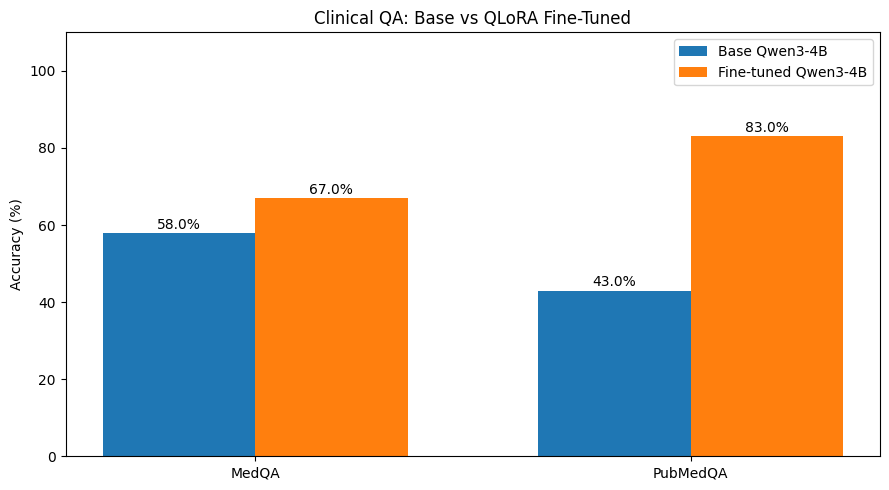

Saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation/accuracy_comparison.png


In [16]:

# ============================================================
# Cell 16: Plot baseline vs fine-tuned accuracy
# ============================================================

tasks = ["MedQA", "PubMedQA"]

base_scores = [
    medqa_metrics["base_accuracy"] * 100,
    pubmedqa_metrics["base_accuracy"] * 100,
]

ft_scores = [
    medqa_metrics["finetuned_accuracy"] * 100,
    pubmedqa_metrics["finetuned_accuracy"] * 100,
]

x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_base = ax.bar(
    x - width / 2,
    base_scores,
    width,
    label="Base Qwen3-4B",
)

bars_ft = ax.bar(
    x + width / 2,
    ft_scores,
    width,
    label="Fine-tuned Qwen3-4B",
)

ax.set_title("Clinical QA: Base vs QLoRA Fine-Tuned")
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(x)
ax.set_xticklabels(tasks)
ax.set_ylim(0, 110)
ax.legend()

for bars in [bars_base, bars_ft]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
        )

plt.tight_layout()

plot_path = RESULTS_DIR / "accuracy_comparison.png"
plt.savefig(plot_path, dpi=150)
plt.show()

print("Saved:", plot_path)


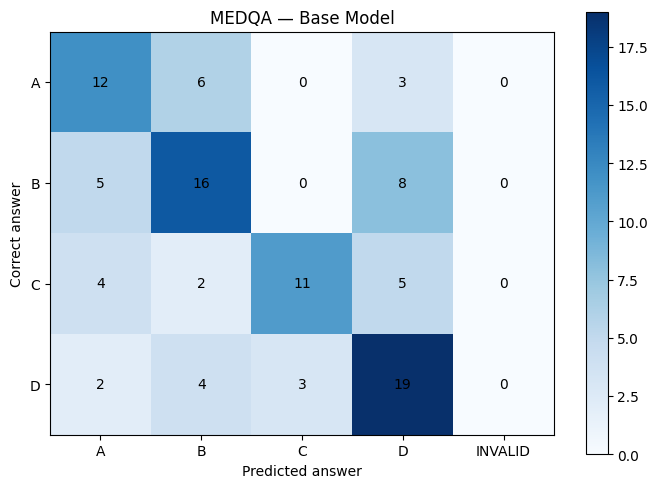

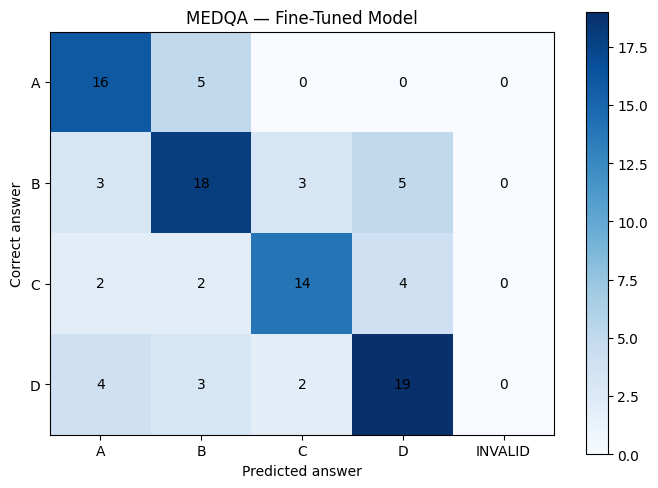

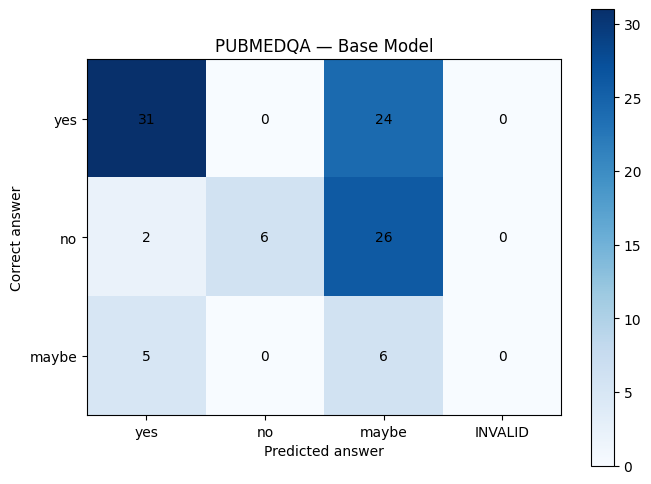

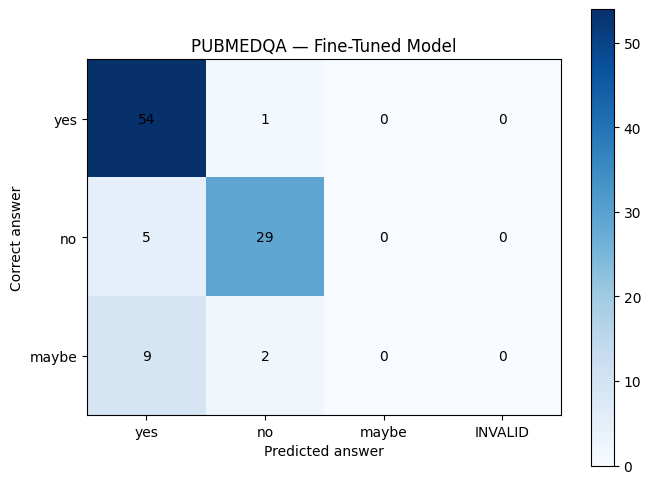

In [17]:

# ============================================================
# Cell 17: Visualize prediction confusion matrices
# ============================================================

def plot_confusion(results, task, prediction_column, title):
    """
    Plot a confusion matrix for one model and task.

    Parameters
    ----------
    results : pandas.DataFrame
        Paired evaluation predictions.
    task : str
        'medqa' or 'pubmedqa'.
    prediction_column : str
        Column containing the model predictions.
    title : str
        Plot title.

    Returns
    -------
    None
        Displays and saves the confusion matrix.
    """
    task_df = results[results["task"] == task]

    if task == "medqa":
        answer_labels = ["A", "B", "C", "D"]
    else:
        answer_labels = ["yes", "no", "maybe"]

    prediction_labels = answer_labels + ["INVALID"]

    expected = task_df["expected"].tolist()

    predicted = (
        task_df[prediction_column]
        .fillna("INVALID")
        .tolist()
    )

    matrix = confusion_matrix(
        expected,
        predicted,
        labels=prediction_labels,
    )

    # The final row is not a possible true label.
    matrix = matrix[:len(answer_labels), :]

    fig, ax = plt.subplots(figsize=(7, 5))

    image = ax.imshow(matrix, cmap="Blues")
    fig.colorbar(image, ax=ax)

    ax.set_xticks(range(len(prediction_labels)))
    ax.set_xticklabels(prediction_labels)

    ax.set_yticks(range(len(answer_labels)))
    ax.set_yticklabels(answer_labels)

    ax.set_xlabel("Predicted answer")
    ax.set_ylabel("Correct answer")
    ax.set_title(title)

    for row_index in range(matrix.shape[0]):
        for col_index in range(matrix.shape[1]):
            ax.text(
                col_index,
                row_index,
                str(matrix[row_index, col_index]),
                ha="center",
                va="center",
            )

    plt.tight_layout()

    filename = (
        f"{task}_{prediction_column}_confusion.png"
    )

    plt.savefig(
        RESULTS_DIR / filename,
        dpi=150,
    )

    plt.show()


for task in ["medqa", "pubmedqa"]:
    plot_confusion(
        comparison_df,
        task,
        "base_prediction",
        f"{task.upper()} — Base Model",
    )

    plot_confusion(
        comparison_df,
        task,
        "finetuned_prediction",
        f"{task.upper()} — Fine-Tuned Model",
    )


In [18]:

# ============================================================
# Cell 18: Categorize prediction changes
# ============================================================

def categorize_prediction(row):
    """
    Classify a paired prediction by correctness transition.

    Parameters
    ----------
    row : pandas.Series
        One paired evaluation record.

    Returns
    -------
    str
        Improvement or regression category.
    """
    base_correct = bool(row["base_correct"])
    ft_correct = bool(row["finetuned_correct"])

    if base_correct and ft_correct:
        return "Both correct"

    if not base_correct and ft_correct:
        return "Fixed by fine-tuning"

    if base_correct and not ft_correct:
        return "Regression after fine-tuning"

    return "Both incorrect"


comparison_df["error_category"] = comparison_df.apply(
    categorize_prediction,
    axis=1,
)

error_summary = pd.crosstab(
    comparison_df["task"],
    comparison_df["error_category"],
)

display(error_summary)

# Inspect examples where fine-tuning introduced an error.
regressions = comparison_df[
    comparison_df["error_category"]
    == "Regression after fine-tuning"
]

print("Regression examples:", len(regressions))

display(
    regressions[
        [
            "task",
            "question",
            "expected",
            "base_prediction",
            "finetuned_prediction",
        ]
    ].head(10)
)

# Save the categorized predictions.
comparison_df.to_csv(
    RESULTS_DIR / "paired_model_predictions.csv",
    index=False,
)


error_category,Both correct,Both incorrect,Fixed by fine-tuning,Regression after fine-tuning
task,,,,
medqa,55,30,12,3
pubmedqa,37,11,46,6


Regression examples: 9


,task,question,expected,base_prediction,finetuned_prediction
48,medqa,A 55-year-old obese woman is referred to the c...,B,B,C
53,medqa,A 23-year-old man comes to the physician for f...,D,D,B
79,medqa,A 56-year-old man comes to the physician for a...,D,D,A
102,pubmedqa,Is Panton-Valentine leucocidin associated with...,maybe,maybe,no
157,pubmedqa,Does responsibility affect the public's valuat...,maybe,maybe,yes
165,pubmedqa,Young-Burgess classification of pelvic ring fr...,maybe,maybe,no
169,pubmedqa,Can APC mutation analysis contribute to therap...,maybe,maybe,yes
198,pubmedqa,CPAP therapy in patients with idiopathic pulmo...,maybe,maybe,yes
199,pubmedqa,Artefacts in 24-h pharyngeal and oesophageal p...,maybe,maybe,yes


In [20]:

# ============================================================
# Cell 19: Evaluate checkpoint regression gates
# ============================================================

def evaluate_regression_gates(metrics, macro_improvement):
    """
    Check whether the fine-tuned model passes QA quality gates.

    Parameters
    ----------
    metrics : list[dict]
        Per-task evaluation metrics.
    macro_improvement : float
        Change in macro accuracy, in percentage points.

    Returns
    -------
    dict
        Individual gate results and overall decision.
    """
    minimum_samples = 100
    maximum_regression_pp = -2.0
    minimum_valid_rate = 0.95

    gates = {
        "macro_improved": macro_improvement > 0,
    }

    for task_metrics in metrics:
        task = task_metrics["task"]

        gates[f"{task}_coverage"] = (
            task_metrics["samples"] >= minimum_samples
        )

        gates[f"{task}_accuracy"] = (
            task_metrics["improvement_pp"]
            >= maximum_regression_pp
        )

        gates[f"{task}_validity"] = (
            task_metrics["finetuned_valid_rate"]
            >= minimum_valid_rate
        )

    passed = all(gates.values())

    return {
        "gates": gates,
        "passed": passed,
        "decision": (
            "PROVISIONAL PASS"
            if passed
            else "HOLD FOR INVESTIGATION"
        ),
    }


gate_result = evaluate_regression_gates(
    [medqa_metrics, pubmedqa_metrics],
    macro_improvement_pp,
)

print("REGRESSION GATE RESULTS")
print("-" * 50)

for gate, passed in gate_result["gates"].items():
    print(f"{gate}: {'PASS' if passed else 'FAIL'}")

print("\nDecision:", gate_result["decision"])


REGRESSION GATE RESULTS
--------------------------------------------------
macro_improved: PASS
medqa_coverage: PASS
medqa_accuracy: PASS
medqa_validity: PASS
pubmedqa_coverage: PASS
pubmedqa_accuracy: PASS
pubmedqa_validity: PASS

Decision: PROVISIONAL PASS


In [21]:

# ============================================================
# Cell 20: Save model evaluation report
# ============================================================

import transformers
import peft

evaluation_report = {
    "project": "Clinical QA QLoRA",
    "experiment": "Base vs full-training adapter",
    "base_model": MODEL_ID,
    "adapter_directory": str(ADAPTER_DIR),
    "training_examples": 11999,
    "training_steps": 1500,
    "lora_rank": 16,
    "evaluation_split": "validation",
    "seed": SEED,
    "max_context": MAX_CONTEXT,
    "max_new_tokens": MAX_NEW_TOKENS,
    "thinking_enabled": False,
    "decoding": "greedy",
    "quantization": "bitsandbytes NF4 4-bit",
    "medqa": medqa_metrics,
    "pubmedqa": pubmedqa_metrics,
    "macro_base_accuracy": macro_base,
    "macro_finetuned_accuracy": macro_finetuned,
    "macro_improvement_pp": macro_improvement_pp,
    "confidence_intervals": confidence_intervals,
    "regression_gates": gate_result,
    "gpu": GPU_NAME,
    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
}

REPORT_FILE = (
    RESULTS_DIR / "model_evaluation_report.json"
)

with open(
    REPORT_FILE,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        evaluation_report,
        file,
        indent=4,
    )

metrics_df.to_csv(
    RESULTS_DIR / "model_comparison_metrics.csv",
    index=False,
)

comparison_df.to_csv(
    RESULTS_DIR / "paired_model_predictions.csv",
    index=False,
)

print("Evaluation report saved:", REPORT_FILE)
print("Model comparison saved successfully.")


Evaluation report saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation/model_evaluation_report.json
Model comparison saved successfully.


In [22]:

# ============================================================
# Cell 21: Generate GitHub-ready evaluation summary
# ============================================================

def percentage(value):
    """
    Format a decimal accuracy as a percentage.

    Parameters
    ----------
    value : float
        Number between 0 and 1.

    Returns
    -------
    str
        Percentage formatted to two decimal places.
    """
    return f"{value * 100:.2f}%"


readme_summary = f"""## Clinical Q&A Model Evaluation

### Model Configuration

- Base model: {MODEL_ID}
- Fine-tuning: QLoRA, rank 16
- Training examples: 11,999
- Training steps: 1,500
- Evaluation: Held-out development/validation data
- Inference: NF4 4-bit, non-thinking, greedy decoding

### Results

| Metric | Base Qwen3-4B | Fine-Tuned Qwen3-4B |
|---|---:|---:|
| MedQA accuracy | {percentage(medqa_metrics['base_accuracy'])} | {percentage(medqa_metrics['finetuned_accuracy'])} |
| PubMedQA accuracy | {percentage(pubmedqa_metrics['base_accuracy'])} | {percentage(pubmedqa_metrics['finetuned_accuracy'])} |
| Macro accuracy | {percentage(macro_base)} | {percentage(macro_finetuned)} |

Macro accuracy improvement: {macro_improvement_pp:+.2f} percentage points.

Evaluation sizes:
- MedQA: {medqa_metrics['samples']}
- PubMedQA: {pubmedqa_metrics['samples']}

Checkpoint development gate: {gate_result['decision']}

### Limitations

- These results are from validation data, not the final test sets.
- This is an educational research model, not a clinical decision system.
- The current evaluation uses short, structured answer labels.
- Quantization and serving optimizations have not yet been evaluated.
"""

README_FILE = RESULTS_DIR / "evaluation_summary.md"

README_FILE.write_text(
    readme_summary,
    encoding="utf-8",
)

print(readme_summary)
print("\nSaved:", README_FILE)


## Clinical Q&A Model Evaluation

### Model Configuration

- Base model: Qwen/Qwen3-4B
- Fine-tuning: QLoRA, rank 16
- Training examples: 11,999
- Training steps: 1,500
- Evaluation: Held-out development/validation data
- Inference: NF4 4-bit, non-thinking, greedy decoding

### Results

| Metric | Base Qwen3-4B | Fine-Tuned Qwen3-4B |
|---|---:|---:|
| MedQA accuracy | 58.00% | 67.00% |
| PubMedQA accuracy | 43.00% | 83.00% |
| Macro accuracy | 50.50% | 75.00% |

Macro accuracy improvement: +24.50 percentage points.

Evaluation sizes:
- MedQA: 100
- PubMedQA: 100

Checkpoint development gate: PROVISIONAL PASS

### Limitations

- These results are from validation data, not the final test sets.
- This is an educational research model, not a clinical decision system.
- The current evaluation uses short, structured answer labels.
- Quantization and serving optimizations have not yet been evaluated.


Saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/results/evaluation/evaluation_summ